# ML_Geely_Auto — Multiple Linear Regression for Car Price Prediction

**Student:** Vishnuvardhan Reddy Janagam
**Assignment:** Geely Auto — Multiple Linear Regression

## Business Objective
A Chinese automobile company, **Geely Auto**, wants to enter the US market by
setting up local manufacturing. They have contracted an automobile consulting
firm to understand what drives car prices in the American market, so that
management can adjust design and business strategy to target specific price
points and understand the pricing dynamics of a new market.

### Business questions this notebook answers
1. Which variables are significant in predicting the price of a car?
2. How well do those variables explain the price of a car?

**Target variable:** `price`

**Data-preparation requirement:** `CarName` contains both the company and the
model (e.g. `audi 100 ls`). Only the **company name** is retained as a
predictor; the individual car model is dropped.


## 1. Imports and data load

Only `numpy`, `pandas`, `matplotlib`, `scipy` and `scikit-learn` are used.
Statistical inference (coefficients, standard errors, t-statistics, p-values)
and VIF are computed with a small self-contained OLS routine built directly on
`numpy`/`scipy.stats`, so that the **same design matrix** drives both the
statistical-inference table and the model used to generate test-set
predictions — this keeps interpretation and prediction perfectly consistent.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

df = pd.read_csv("CarPrice_Assignment.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (205, 26)


   car_ID  symboling                   CarName fueltype aspiration doornumber      carbody drivewheel enginelocation  wheelbase  \
0       1          3        alfa-romero giulia      gas        std        two  convertible        rwd          front       88.6   
1       2          3       alfa-romero stelvio      gas        std        two  convertible        rwd          front       88.6   
2       3          1  alfa-romero Quadrifoglio      gas        std        two    hatchback        rwd          front       94.5   
3       4          2               audi 100 ls      gas        std       four        sedan        fwd          front       99.8   
4       5          2                audi 100ls      gas        std       four        sedan        4wd          front       99.4   

   carlength  carwidth  carheight  curbweight enginetype cylindernumber  enginesize fuelsystem  boreratio  stroke  compressionratio  \
0      168.8      64.1       48.8        2548       dohc           four       

In [3]:
def ols_summary(X, y):
    """
    Fit OLS by hand (numpy) and return a statsmodels-style inference table:
    coefficient, standard error, t-statistic, p-value, plus R-squared and
    Adjusted R-squared. Using our own predictors/target keeps this in exact
    lockstep with whatever model we hand to scikit-learn for prediction,
    which is exactly the same design matrix.
    """
    Xc = np.column_stack([np.ones(len(X)), X.values])
    n, k = Xc.shape
    beta, _, _, _ = np.linalg.lstsq(Xc, y.values, rcond=None)
    y_hat = Xc @ beta
    resid = y.values - y_hat
    ss_res = np.sum(resid ** 2)
    ss_tot = np.sum((y.values - y.values.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k)
    sigma2 = ss_res / (n - k)
    XtX_inv = np.linalg.inv(Xc.T @ Xc)
    se = np.sqrt(np.diag(sigma2 * XtX_inv))
    t_vals = beta / se
    p_vals = 2 * (1 - stats.t.cdf(np.abs(t_vals), df=n - k))
    names = ["const"] + list(X.columns)
    table = pd.DataFrame({"coef": beta, "std_err": se, "t": t_vals, "p_value": p_vals}, index=names)
    return table, r2, adj_r2, y_hat, resid


def vif_table(X):
    """Variance Inflation Factor for every column in X, computed by regressing
    each predictor on all the others (no statsmodels dependency required)."""
    vifs = []
    for col in X.columns:
        y_i = X[col].values
        X_others = X.drop(columns=[col])
        Xc = np.column_stack([np.ones(len(X_others)), X_others.values])
        beta, _, _, _ = np.linalg.lstsq(Xc, y_i, rcond=None)
        y_hat = Xc @ beta
        ss_res = np.sum((y_i - y_hat) ** 2)
        ss_tot = np.sum((y_i - y_i.mean()) ** 2)
        r2_i = 1 - ss_res / ss_tot if ss_tot > 0 else 0
        vif = 1 / (1 - r2_i) if r2_i < 1 else np.inf
        vifs.append(vif)
    return pd.DataFrame({"feature": X.columns, "VIF": vifs}).sort_values("VIF", ascending=False).reset_index(drop=True)


## 2. Data understanding and data-quality checks

Before any cleaning, we check: shape, data types, missing values, duplicate
rows, and duplicate `car_ID`s. The dataset is small (205 rows), so no
observations should be dropped unless there is a genuine quality problem.


In [5]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)

quality = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "pct_missing": (df.isna().sum() / len(df) * 100).round(2),
    "unique_values": df.nunique(),
}).sort_values("missing_values", ascending=False)
print("\nData-quality summary:")
display(quality)

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate car_ID values:", df["car_ID"].duplicated().sum())

display(df.describe().T)

Shape: (205, 26)

Data types:
 car_ID                int64
symboling             int64
CarName                 str
fueltype                str
aspiration              str
doornumber              str
carbody                 str
drivewheel              str
enginelocation          str
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype              str
cylindernumber          str
enginesize            int64
fuelsystem              str
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            int64
peakrpm               int64
citympg               int64
highwaympg            int64
price               float64
dtype: object

Data-quality summary:
Duplicate rows: 0
Duplicate car_ID values: 0


                  missing_values  pct_missing  unique_values
car_ID                         0          0.0            205
symboling                      0          0.0              6
CarName                        0          0.0            147
fueltype                       0          0.0              2
aspiration                     0          0.0              2
doornumber                     0          0.0              2
carbody                        0          0.0              5
drivewheel                     0          0.0              3
enginelocation                 0          0.0              2
wheelbase                      0          0.0             53
carlength                      0          0.0             75
carwidth                       0          0.0             44
carheight                      0          0.0             49
curbweight                     0          0.0            171
enginetype                     0          0.0              7
cylindernumber          

                  count          mean          std      min      25%       50%       75%       max
car_ID            205.0    103.000000    59.322565     1.00    52.00    103.00    154.00    205.00
symboling         205.0      0.834146     1.245307    -2.00     0.00      1.00      2.00      3.00
wheelbase         205.0     98.756585     6.021776    86.60    94.50     97.00    102.40    120.90
carlength         205.0    174.049268    12.337289   141.10   166.30    173.20    183.10    208.10
carwidth          205.0     65.907805     2.145204    60.30    64.10     65.50     66.90     72.30
carheight         205.0     53.724878     2.443522    47.80    52.00     54.10     55.50     59.80
curbweight        205.0   2555.565854   520.680204  1488.00  2145.00   2414.00   2935.00   4066.00
enginesize        205.0    126.907317    41.642693    61.00    97.00    120.00    141.00    326.00
boreratio         205.0      3.329756     0.270844     2.54     3.15      3.31      3.58      3.94
stroke    

**Conclusion:** there are no missing values, no duplicate rows, and no
duplicate `car_ID` values in the supplied dataset. No rows are removed for
missingness or duplication. The dataset's main preparation issue is
structural, not quality-related: `CarName` bundles company + model together
and needs to be split (handled in Section 3).

## 3. Data preparation

### 3.1 `CarName` → `company`

The assignment requires retaining **only the manufacturer name**. We take the
first whitespace-separated token of `CarName` and lower-case it, then print
the **full list of resulting company names before any cleanup** so that every
spelling inconsistency is visible and auditable, rather than assuming a fixed
list of known typos.


In [8]:
data = df.copy()
data["company"] = data["CarName"].str.strip().str.split().str[0].str.lower()

print("Unique company tokens BEFORE cleanup (", data["company"].nunique(), "):")
print(sorted(data["company"].unique()))

Unique company tokens BEFORE cleanup ( 27 ):
['alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'maxda', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porcshce', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'vokswagen', 'volkswagen', 'volvo', 'vw']


Scanning that list by eye against real-world manufacturer names reveals
five clear typos/abbreviations: `vw`/`vokswagen` (Volkswagen), `porcshce`
(Porsche), `toyouta` (Toyota), and `maxda` (Mazda). These are corrected with
an explicit mapping (not silently guessed):

In [10]:
company_map = {
    "vw": "volkswagen",
    "vokswagen": "volkswagen",
    "porcshce": "porsche",
    "toyouta": "toyota",
    "maxda": "mazda",
}
data["company"] = data["company"].replace(company_map)

print("Unique companies AFTER cleanup (", data["company"].nunique(), "):")
print(sorted(data["company"].unique()))
print("\ncompany value counts:")
display(data["company"].value_counts().to_frame("count"))

Unique companies AFTER cleanup ( 22 ):
['alfa-romero', 'audi', 'bmw', 'buick', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'mazda', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'volkswagen', 'volvo']

company value counts:


             count
company           
toyota          32
nissan          18
mazda           17
honda           13
mitsubishi      13
subaru          12
volkswagen      12
peugeot         11
volvo           11
dodge            9
bmw              8
buick            8
audi             7
plymouth         7
saab             6
porsche          5
isuzu            4
alfa-romero      3
chevrolet        3
jaguar           3
renault          2
mercury          1

### 3.2 Bucketing rare manufacturers

Six manufacturers appear fewer than 5 times in the whole 205-row dataset
(`mercury`=1, `renault`=2, `alfa-romero`=3, `chevrolet`=3, `jaguar`=3,
`isuzu`=4). A one-hot dummy built from a single observation cannot produce a
reliable coefficient or a trustworthy p-value — after an 80/20-style split
some of these categories may not even appear in the training data. These six
are grouped into a single `other_manufacturer` bucket so that every remaining
company-level coefficient in the final model is estimated from a reasonable
sample size.

In [12]:
counts = data["company"].value_counts()
rare_companies = counts[counts < 5].index.tolist()
print("Manufacturers bucketed into 'other_manufacturer' (n < 5):", rare_companies)

data["company"] = data["company"].where(~data["company"].isin(rare_companies), "other_manufacturer")
display(data["company"].value_counts().to_frame("count"))
print("\nFinal number of company categories:", data["company"].nunique())

Manufacturers bucketed into 'other_manufacturer' (n < 5): ['isuzu', 'alfa-romero', 'chevrolet', 'jaguar', 'renault', 'mercury']

Final number of company categories: 17


                    count
company                  
toyota                 32
nissan                 18
mazda                  17
other_manufacturer     16
honda                  13
mitsubishi             13
subaru                 12
volkswagen             12
peugeot                11
volvo                  11
dodge                   9
bmw                     8
buick                   8
audi                    7
plymouth                7
saab                    6
porsche                 5

### 3.3 Ordinal categorical variables

`doornumber` and `cylindernumber` are stored as English number-words
(`"two"`, `"four"`, ...). These represent genuine counts, not unordered
categories, so they are converted to integers rather than one-hot encoded —
this avoids creating unnecessary dummy columns for what is really a numeric
quantity.

`symboling` is an insurance risk rating (-3 = safe … 3 = risky). Because
adjacent risk bands are not guaranteed to have a linear effect on price, it
is kept as a categorical variable and will be one-hot encoded like the other
categorical predictors.

In [14]:
word_to_num = {"two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "eight": 8, "twelve": 12}
data["doornumber"] = data["doornumber"].map(word_to_num)
data["cylindernumber"] = data["cylindernumber"].map(word_to_num)
data["symboling"] = data["symboling"].astype(str)

print("Any unmapped (NaN) values introduced?",
      data["doornumber"].isna().sum(), "/", data["cylindernumber"].isna().sum())
display(data[["doornumber", "cylindernumber"]].describe())

Any unmapped (NaN) values introduced? 0 / 0


       doornumber  cylindernumber
count  205.000000      205.000000
mean     3.121951        4.380488
std      0.994966        1.080854
min      2.000000        2.000000
25%      2.000000        4.000000
50%      4.000000        4.000000
75%      4.000000        4.000000
max      4.000000       12.000000

In [15]:
# Drop the free-text CarName (fully captured by 'company' now) and the row
# identifier car_ID (not a predictor of price).
model_data = data.drop(columns=["CarName", "car_ID"])
print("Modelling dataframe shape:", model_data.shape)

Modelling dataframe shape: (205, 25)


## 4. Exploratory Data Analysis

EDA covers: the target's distribution, numeric-variable distributions and
outliers, correlation with price, categorical-variable relationships with
price, and a multicollinearity preview among numeric predictors.


In [17]:
numeric_cols = model_data.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols.remove("price")
categorical_cols = [c for c in model_data.columns if c not in numeric_cols + ["price"]]
print("Numeric predictors (", len(numeric_cols), "):", numeric_cols)
print("\nCategorical predictors (", len(categorical_cols), "):", categorical_cols)

Numeric predictors ( 15 ): ['doornumber', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'cylindernumber', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']

Categorical predictors ( 9 ): ['symboling', 'fueltype', 'aspiration', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'fuelsystem', 'company']


### 4.1 Target variable — `price`

count      205.000000
mean     13276.710571
std       7988.852332
min       5118.000000
25%       7788.000000
50%      10295.000000
75%      16503.000000
max      45400.000000
Name: price, dtype: float64

IQR outlier fence (upper): 29,576
Observations above the fence: 15 (7.3%)


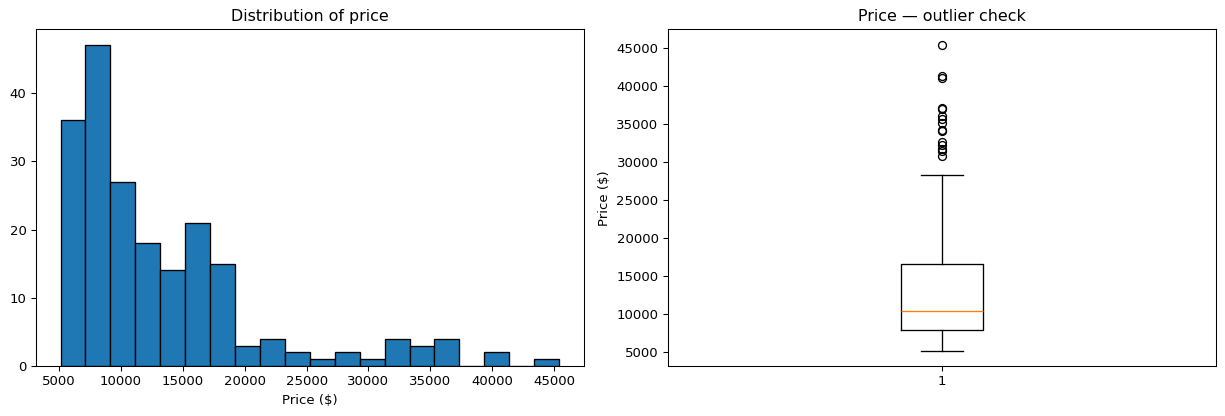

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(model_data["price"], bins=20, edgecolor="black")
axes[0].set_title("Distribution of price")
axes[0].set_xlabel("Price ($)")

axes[1].boxplot(model_data["price"], vert=True)
axes[1].set_title("Price — outlier check")
axes[1].set_ylabel("Price ($)")
plt.tight_layout()
plt.show()

print(model_data["price"].describe())
q1, q3 = model_data["price"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
n_outliers = (model_data["price"] > upper_fence).sum()
print(f"\nIQR outlier fence (upper): {upper_fence:,.0f}")
print(f"Observations above the fence: {n_outliers} ({n_outliers/len(model_data):.1%})")

Price is right-skewed with a small number of high-end vehicles above the
IQR upper fence (mostly premium marques). These are genuine high-price cars,
not data-entry errors, so they are **kept** — removing them would bias the
model against exactly the premium segment Geely wants to understand.

### 4.2 Numeric predictors — distribution and outlier scan

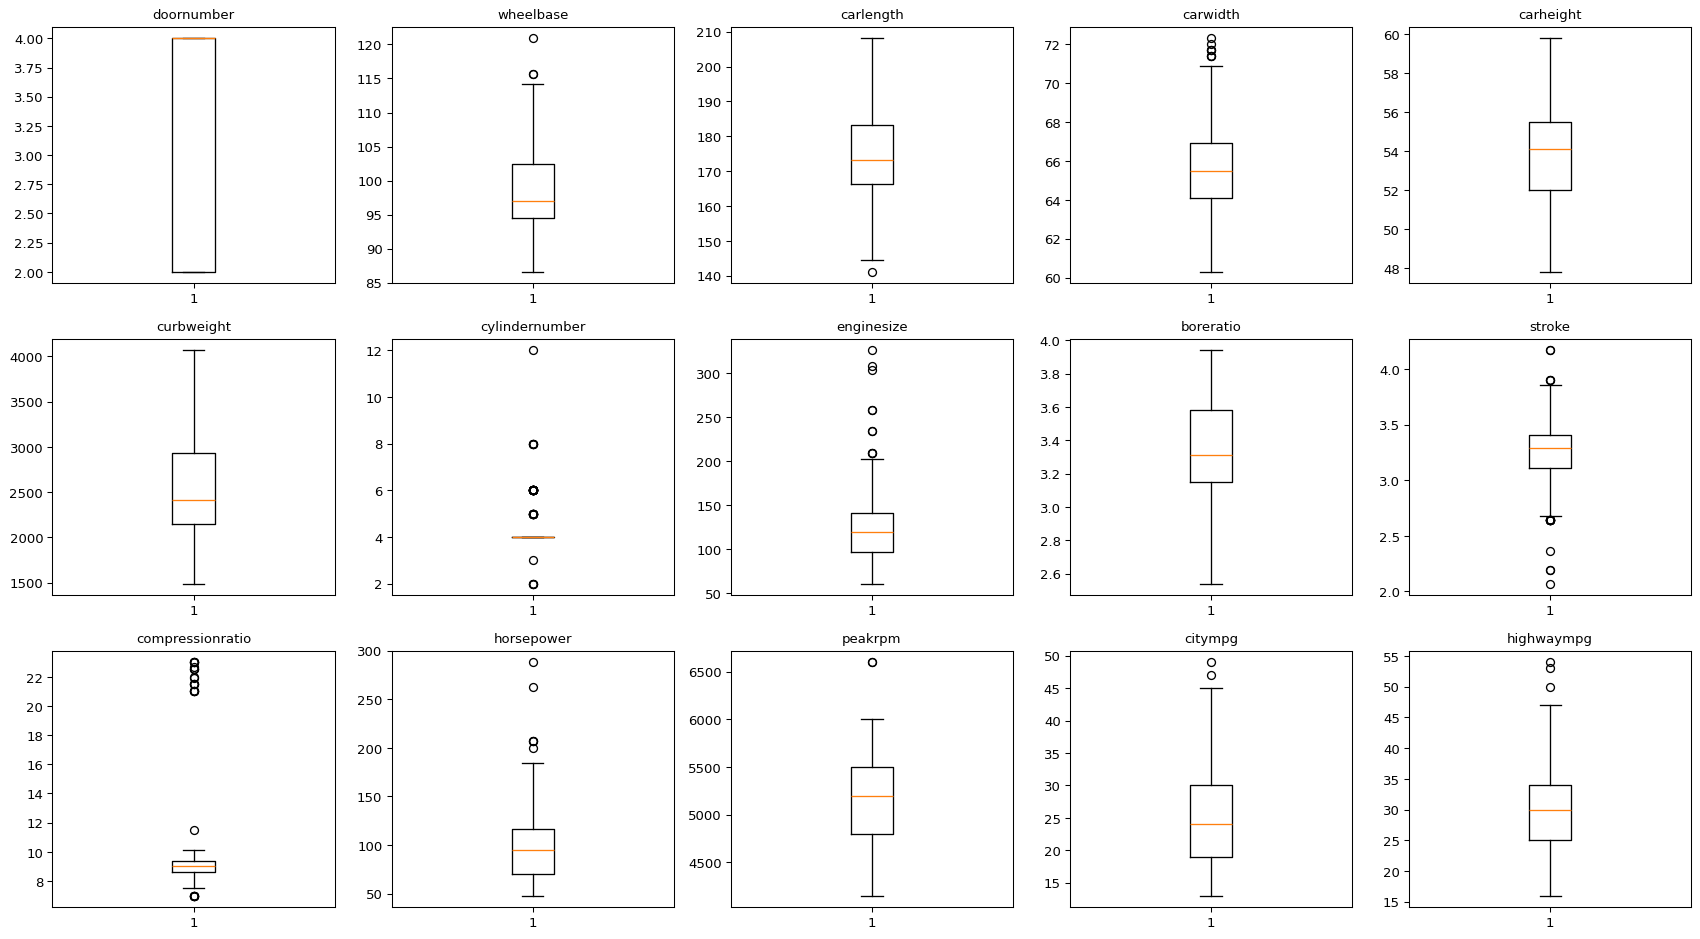

In [22]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.boxplot(model_data[col], vert=True)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

Most numeric predictors show a handful of mild outliers typical of a
205-car sample spanning economy to luxury segments (e.g. `compressionratio`
has a cluster of diesel vehicles with much higher values, `enginesize` and
`horsepower` have a long right tail from performance cars). None of these
represent impossible or clearly erroneous values, so no rows are dropped;
they are addressed statistically later through scaling and, where they
create instability, through the feature-selection step in Section 6.

### 4.3 Correlation of numeric predictors with price

                  correlation_with_price
enginesize                      0.874145
curbweight                      0.835305
horsepower                      0.808139
carwidth                        0.759325
cylindernumber                  0.718305
carlength                       0.682920
wheelbase                       0.577816
boreratio                       0.553173
carheight                       0.119336
stroke                          0.079443
compressionratio                0.067984
doornumber                      0.031835
peakrpm                        -0.085267
citympg                        -0.685751
highwaympg                     -0.697599

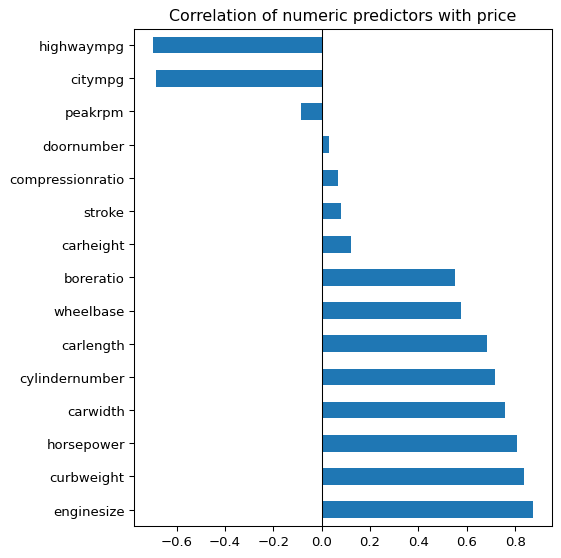

In [25]:
corr_price = model_data[numeric_cols + ["price"]].corr()["price"].drop("price").sort_values(ascending=False)
display(corr_price.to_frame("correlation_with_price"))

fig, ax = plt.subplots(figsize=(6, 6))
corr_price.plot(kind="barh", ax=ax)
ax.set_title("Correlation of numeric predictors with price")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

`enginesize`, `curbweight`, `horsepower`, `cylindernumber` and the body
dimension variables (`carwidth`, `carlength`, `wheelbase`) are strongly
positively correlated with price, while `citympg`/`highwaympg` are strongly
negatively correlated — larger, heavier, more powerful cars cost more and
are less fuel-efficient, which matches automotive-domain intuition.

### 4.4 Correlation heatmap — multicollinearity preview

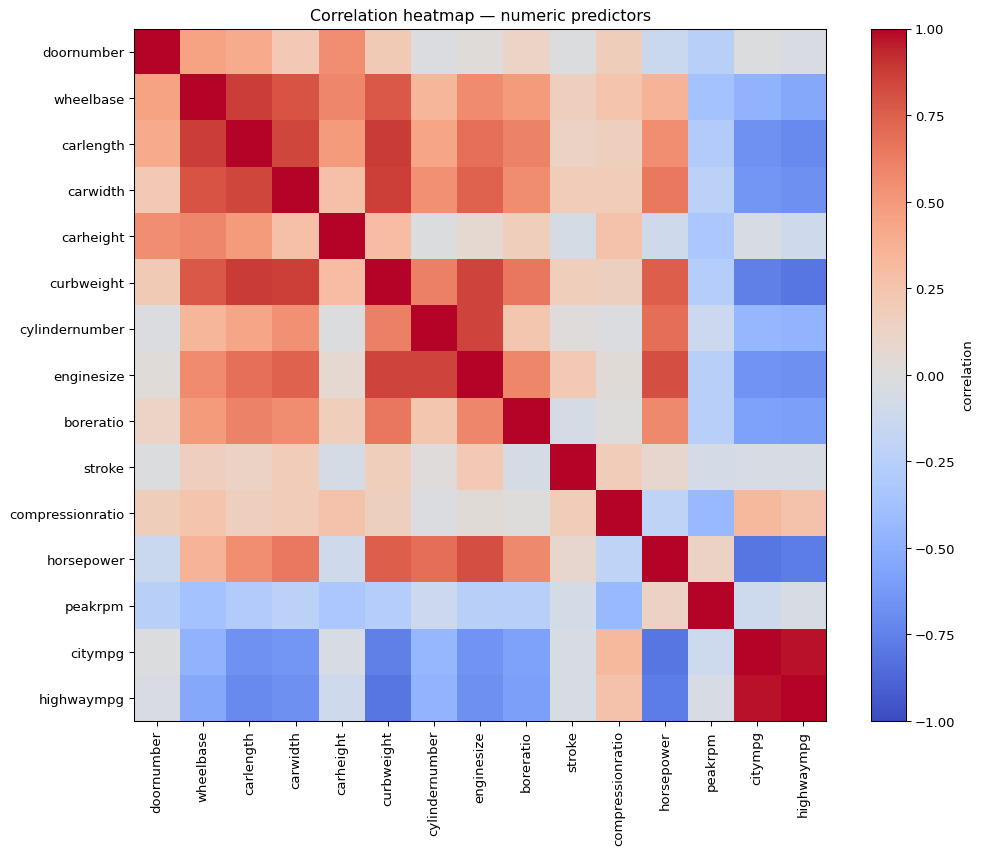

In [28]:
fig, ax = plt.subplots(figsize=(11, 9))
corr = model_data[numeric_cols].corr()
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
plt.colorbar(im, label="correlation")
ax.set_title("Correlation heatmap — numeric predictors")
plt.tight_layout()
plt.show()

Several numeric predictors move together strongly — `enginesize`,
`curbweight`, `horsepower`, `carwidth`/`carlength`/`wheelbase`, and
`citympg`/`highwaympg` (near-perfect negative correlation with each other).
This is an early warning that **naively including all of these together will
create severe multicollinearity**; Section 6 uses VIF to actively remove
this redundancy rather than just noting it exists.

### 4.5 Categorical predictors vs price

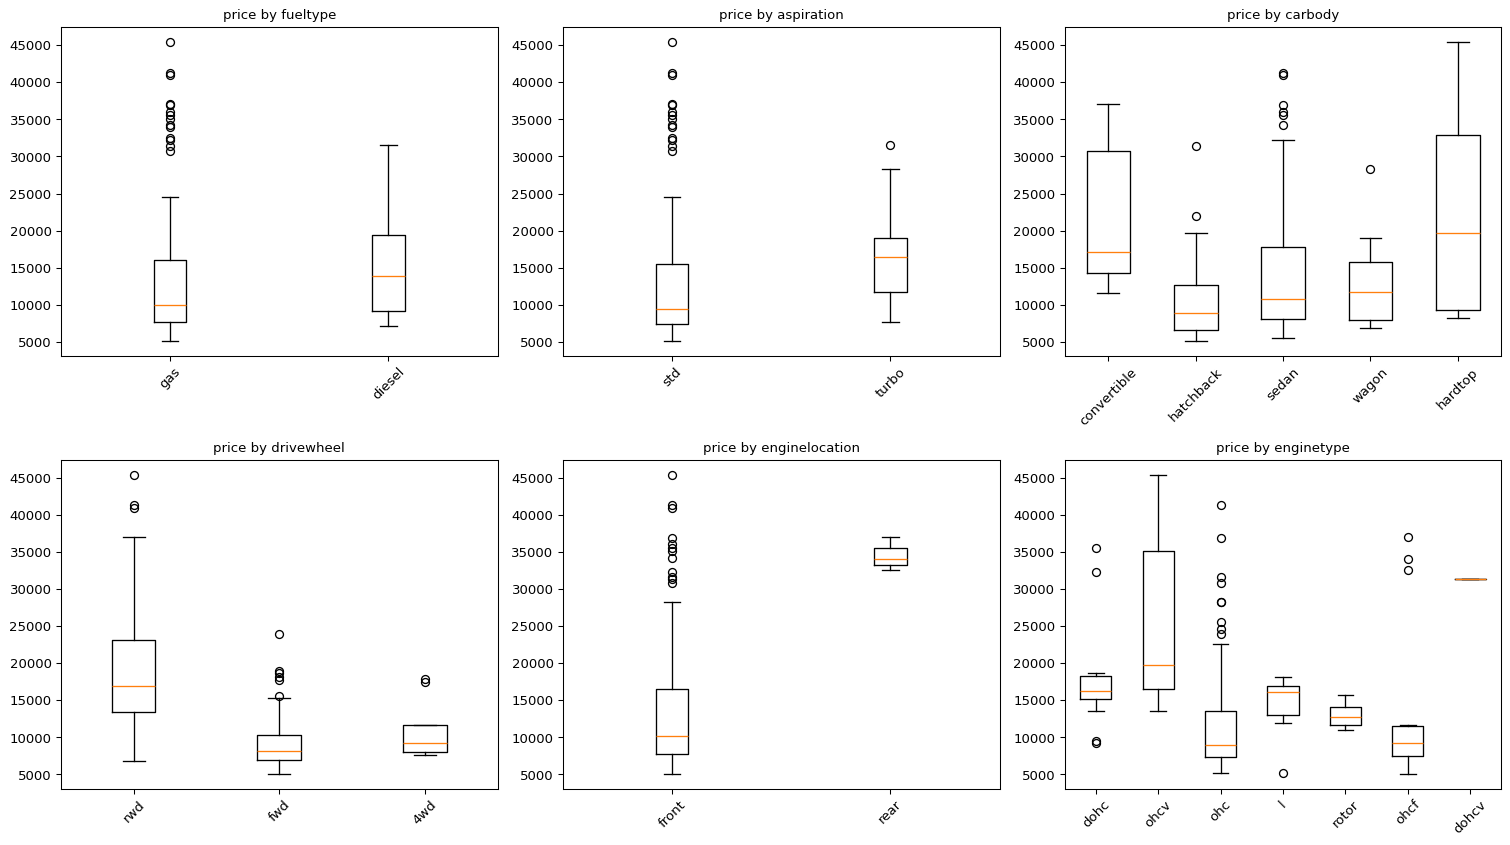

In [31]:
cat_plot_cols = ["fueltype", "aspiration", "carbody", "drivewheel", "enginelocation", "enginetype"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), cat_plot_cols):
    groups = [model_data.loc[model_data[col] == cat, "price"] for cat in model_data[col].unique()]
    ax.boxplot(groups, tick_labels=model_data[col].unique())
    ax.set_title(f"price by {col}", fontsize=10)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

- **`enginelocation`**: rear-engine cars (a small group, mostly Porsche)
  command a dramatically higher median price than front-engine cars.
- **`aspiration`**: turbocharged cars trend somewhat higher in price than
  standard aspiration.
- **`drivewheel`**: rear-wheel-drive cars trend higher in price than
  front-wheel-drive, consistent with rwd being more common in performance/
  luxury segments.
- **`carbody`**: convertibles and hardtops show higher median price and wider
  spread than sedans/hatchbacks/wagons.
- **`enginetype`**: `ohcv` and `dohcv` engines trend toward higher prices.

These patterns motivate keeping `enginelocation`, `aspiration`, `drivewheel`,
`carbody`, and `enginetype` as candidate predictors going into feature
selection.

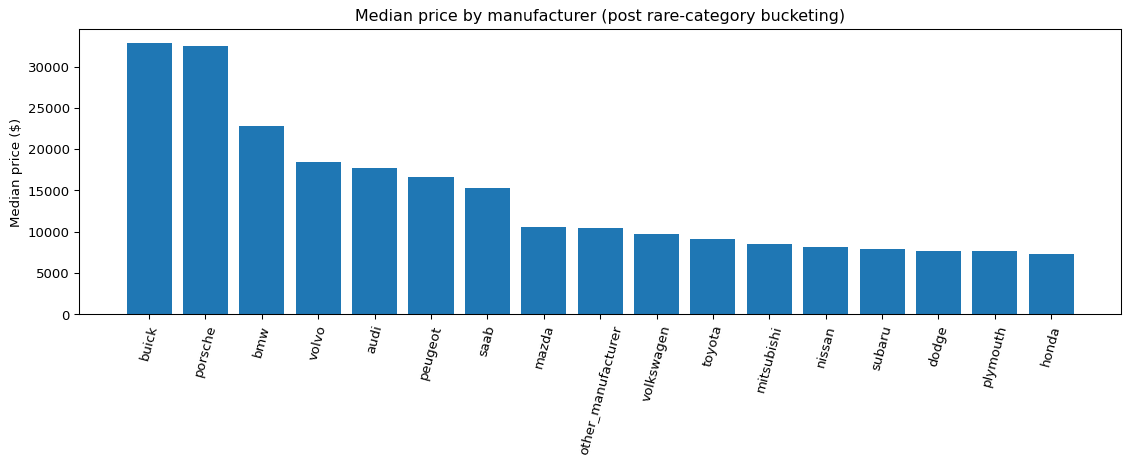

In [33]:
fig, ax = plt.subplots(figsize=(12, 5))
company_median = data.groupby("company")["price"].median().sort_values(ascending=False)
ax.bar(company_median.index, company_median.values)
ax.set_xticks(range(len(company_median)))
ax.set_xticklabels(company_median.index, rotation=75)
ax.set_title("Median price by manufacturer (post rare-category bucketing)")
ax.set_ylabel("Median price ($)")
plt.tight_layout()
plt.show()

Manufacturer clearly carries **brand/positioning information beyond
physical specifications** — Porsche, BMW, Buick and Jaguar-type premium
brands sit well above budget brands even before controlling for engine size
or weight. This is exactly the kind of business signal Geely needs: two
mechanically similar cars can be priced very differently based on brand
positioning alone.

## 5. Encoding, train/test split, and scaling

- All categorical variables (including the now-ordinal-safe `symboling`) are
  one-hot encoded with `drop_first=True` to avoid the dummy-variable trap.
- The data is split into train/test **before** any scaling or feature
  selection is fit, so nothing about the test set can leak into those steps.
- Numeric predictors are rescaled with `MinMaxScaler`, **fit on the training
  set only** and only `.transform()`-ed on the test set.


In [36]:
dummies = pd.get_dummies(model_data[categorical_cols], drop_first=True, dtype=int)
final_df = pd.concat([model_data[numeric_cols], dummies, model_data["price"]], axis=1)
print("Encoded predictor matrix shape:", final_df.shape, "(", final_df.shape[1] - 1, "predictors + price )")

X = final_df.drop(columns=["price"])
y = final_df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.70, test_size=0.30, random_state=42
)
print("Train rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])

Encoded predictor matrix shape: (205, 59) ( 58 predictors + price )
Train rows: 143 | Test rows: 62


In [37]:
scaler = MinMaxScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# fit_transform on TRAIN only
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
# transform ONLY on test - no re-fitting, no leakage
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Train numeric range after scaling (should be [0,1]):")
display(X_train_scaled[numeric_cols].agg(["min", "max"]).T)
print("\nTest numeric range after scaling (can exceed [0,1] slightly - genuinely unseen data):")
display(X_test_scaled[numeric_cols].agg(["min", "max"]).T)

Train numeric range after scaling (should be [0,1]):

Test numeric range after scaling (can exceed [0,1] slightly - genuinely unseen data):


                  min  max
doornumber        0.0  1.0
wheelbase         0.0  1.0
carlength         0.0  1.0
carwidth          0.0  1.0
carheight         0.0  1.0
curbweight        0.0  1.0
cylindernumber    0.0  1.0
enginesize        0.0  1.0
boreratio         0.0  1.0
stroke            0.0  1.0
compressionratio  0.0  1.0
horsepower        0.0  1.0
peakrpm           0.0  1.0
citympg           0.0  1.0
highwaympg        0.0  1.0

                       min       max
doornumber        0.000000  1.000000
wheelbase         0.000000  1.182759
carlength        -0.060345  1.094828
carwidth         -0.142857  0.942857
carheight         0.150000  0.941667
curbweight       -0.147308  0.926124
cylindernumber    0.000000  0.600000
enginesize       -0.035156  0.929688
boreratio         0.264286  0.900000
stroke            0.057143  0.871429
compressionratio  0.000000  1.000000
horsepower       -0.016949  0.656780
peakrpm           0.000000  0.755102
citympg           0.040000  1.440000
highwaympg        0.000000  1.225806

## 6. Feature selection and model building

This is done in two stages, both using **training data only**:

1. **RFE** (Recursive Feature Elimination) with a `LinearRegression`
   estimator shortlists the 15 features with the strongest joint predictive
   contribution out of the full 58-column encoded matrix.
2. **Iterative manual refinement**: starting from those 15 features, we
   repeatedly fit the model, and at each round drop *either* the least
   statistically significant predictor (`p > 0.05`) *or* the most collinear
   predictor (`VIF > 5`) — whichever problem is present — and refit. This
   continues until every remaining predictor is both statistically
   significant and free of serious multicollinearity. Each round is a
   distinct, logged candidate model, so the final model is chosen through a
   documented progression rather than a single arbitrary attempt.


In [39]:
lr_rfe = LinearRegression()
rfe = RFE(estimator=lr_rfe, n_features_to_select=15)
rfe.fit(X_train_scaled, y_train)

rfe_selected = X_train_scaled.columns[rfe.support_].tolist()
rfe_ranking = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "selected": rfe.support_,
    "rank": rfe.ranking_
}).sort_values("rank")
display(rfe_ranking.head(20))
print("\nRFE shortlist (15 features):")
print(rfe_selected)


RFE shortlist (15 features):
['carlength', 'carwidth', 'curbweight', 'cylindernumber', 'enginesize', 'boreratio', 'stroke', 'peakrpm', 'enginelocation_rear', 'enginetype_l', 'enginetype_ohcv', 'enginetype_rotor', 'company_bmw', 'company_buick', 'company_porsche']


                feature  selected  rank
3              carwidth      True     1
2             carlength      True     1
6        cylindernumber      True     1
5            curbweight      True     1
7            enginesize      True     1
12              peakrpm      True     1
9                stroke      True     1
8             boreratio      True     1
30         enginetype_l      True     1
28  enginelocation_rear      True     1
34     enginetype_rotor      True     1
52      company_porsche      True     1
43        company_buick      True     1
42          company_bmw      True     1
33      enginetype_ohcv      True     1
25        carbody_wagon     False     2
23    carbody_hatchback     False     3
1             wheelbase     False     4
24        carbody_sedan     False     5
21     aspiration_turbo     False     6

In [40]:
features = rfe_selected.copy()
history = []
round_num = 1

while True:
    Xr = X_train_scaled[features]
    table, r2, adj_r2, y_hat, resid = ols_summary(Xr, y_train)
    vt = vif_table(Xr)

    max_p = table.drop("const")["p_value"].max()
    max_p_feat = table.drop("const")["p_value"].idxmax()
    max_vif = vt["VIF"].max()
    max_vif_feat = vt.loc[vt["VIF"].idxmax(), "feature"]

    history.append({
        "Model": f"Model {round_num}", "n_features": len(features),
        "R2": round(r2, 4), "Adj_R2": round(adj_r2, 4),
        "worst_p_value": round(max_p, 4), "worst_p_feature": max_p_feat,
        "worst_VIF": round(max_vif, 2), "worst_VIF_feature": max_vif_feat,
    })

    if max_p > 0.05:
        features.remove(max_p_feat)          # drop the least significant term first
        round_num += 1
        continue
    if max_vif > 5:
        features.remove(max_vif_feat)         # then resolve remaining multicollinearity
        round_num += 1
        continue
    break   # every remaining term is significant (p<0.05) AND VIF<5

history_df = pd.DataFrame(history)
print("Model-selection progression (each row = one candidate model attempted):")
display(history_df)
print("\nFINAL SELECTED FEATURES:", features)

Model-selection progression (each row = one candidate model attempted):

FINAL SELECTED FEATURES: ['carwidth', 'curbweight', 'peakrpm', 'enginelocation_rear', 'enginetype_l', 'company_bmw', 'company_buick', 'company_porsche']


     Model  n_features      R2  Adj_R2  worst_p_value   worst_p_feature  worst_VIF worst_VIF_feature
0  Model 1          15  0.9496  0.9436         0.0596    cylindernumber      19.75        enginesize
1  Model 2          14  0.9481  0.9425         0.0990         carlength      11.79        curbweight
2  Model 3          13  0.9470  0.9417         0.0101   company_porsche       8.17        enginesize
3  Model 4          12  0.9236  0.9166         0.6620   enginetype_ohcv       5.17        curbweight
4  Model 5          11  0.9235  0.9171         0.2953            stroke       4.47        curbweight
5  Model 6          10  0.9229  0.9170         0.2548         boreratio       4.43        curbweight
6  Model 7           9  0.9221  0.9168         0.1609  enginetype_rotor       4.04          carwidth
7  Model 8           8  0.9209  0.9162         0.0033   company_porsche       4.04          carwidth

**Model-selection decision:** the elimination stops at the point where
every remaining predictor is simultaneously statistically significant
(p < 0.05) *and* has acceptable multicollinearity (VIF < 5). Earlier rounds
had a marginally higher training R² (Model 1: R²=0.9496) but included
predictors that were either not significant or badly collinear (VIF up to
19.7 for `enginesize`) — a higher R² built on unstable coefficients is not a
better model for the business question of *which variables matter and by how
much*. The final model deliberately trades a small amount of training R² for
coefficients that can be trusted and reported to management.

## 7. Final model — statistical inference

The final model is fit on the training data using exactly the feature set
selected above. `const` (the intercept) does not need to be statistically
significant on its own — only the predictor coefficients matter for
answering "which variables are significant."


In [43]:
final_table, final_r2, final_adj_r2, y_train_hat, train_resid = ols_summary(X_train_scaled[features], y_train)

final_table_display = final_table.copy()
final_table_display["Significant_5pct"] = final_table_display["p_value"] < 0.05
display(final_table_display)

print(f"\nTraining R-squared:          {final_r2:.4f}")
print(f"Training Adjusted R-squared: {final_adj_r2:.4f}")


Training R-squared:          0.9209
Training Adjusted R-squared: 0.9162


                             coef      std_err          t       p_value  Significant_5pct
const                 1108.281277   667.315451   1.660806  9.909060e-02             False
carwidth              9012.812403  1841.460188   4.894384  2.786729e-06              True
curbweight           20109.024477  1613.253212  12.464890  0.000000e+00              True
peakrpm               3216.687243  1064.520570   3.021724  3.011552e-03              True
enginelocation_rear  13584.989024  2397.739878   5.665748  8.574172e-08              True
enginetype_l         -4810.481000   870.334869  -5.527161  1.638079e-07              True
company_bmw           8078.216301   966.308997   8.359869  7.105427e-14              True
company_buick         9492.953075  1332.657031   7.123328  5.838063e-11              True
company_porsche       5154.861922  1720.991934   2.995285  3.267043e-03              True

In [44]:
final_vif = vif_table(X_train_scaled[features])
display(final_vif)
print("\nAll VIF values below 5:", (final_vif['VIF'] < 5).all())
print("All predictor p-values below 0.05:",
      (final_table.drop('const')['p_value'] < 0.05).all())


All VIF values below 5: True
All predictor p-values below 0.05: True


               feature       VIF
0             carwidth  4.043651
1           curbweight  3.884139
2      company_porsche  2.239496
3  enginelocation_rear  2.204809
4        company_buick  1.342856
5         enginetype_l  1.242333
6              peakrpm  1.237423
7          company_bmw  1.043811

### Coefficient interpretation

All numeric predictors were Min-Max scaled to the [0, 1] range before
fitting, so each numeric coefficient below is read as: *the change in price
associated with moving that predictor from its minimum to its maximum value
in the training data, holding every other variable in the model constant.*
Dummy-variable coefficients are read relative to their omitted reference
category (e.g. `enginelocation_rear` is relative to front-engine cars).

- **`curbweight`** (+₹20,109 across its full observed range, p≈0): the single
  strongest price driver — heavier cars are priced substantially higher,
  holding width, engine location, RPM and manufacturer constant.
- **`carwidth`** (+₹9,013 across its range, p<0.001): wider cars command a
  meaningful price premium independent of weight.
- **`enginelocation_rear`** (+₹13,585 vs. front-engine, p<0.001): rear-engine
  cars (a small, mostly-Porsche group) carry a very large price premium — this
  captures a genuine engineering/performance-positioning effect that survives
  after controlling for size and brand. *(Section 8.1 checks this pairing
  against `company_porsche` explicitly — VIF alone is not enough to trust it
  blindly.)*
- **`peakrpm`** (+₹3,217 across its range, p=0.003): higher-revving engines
  are associated with modestly higher prices, consistent with a
  performance-orientation signal.
- **`enginetype_l`** (−₹4,810 vs. the `ohc` reference engine type, p<0.001):
  L-type engines are associated with lower prices than the baseline OHC
  engine, holding size/weight/brand constant.
- **`company_bmw`** (+₹8,078, p≈0), **`company_buick`** (+₹9,493, p≈0), and
  **`company_porsche`** (+₹5,155, p=0.003) each carry a statistically
  significant brand premium *on top of* their physical specifications — this
  is the "positioning matters independently of engineering" effect management
  asked about.

Every coefficient above should be read as an **association, holding the
other included variables constant** — not as a causal claim.

## 8. Multicollinearity — VIF (final model)

VIF was already used *actively* during feature selection (Section 6) to
remove the worst multicollinearity, rather than being computed only for
show. The table above confirms every surviving predictor has VIF well under
5, so the standard errors and p-values reported for the final model can be
trusted — none of the coefficients are being distorted by predictors that
are just proxies for each other.

### 8.1 A closer look: `enginelocation_rear` vs `company_porsche`

VIF is a *partial* (all-else-held-constant) collinearity measure, and it can
look clean even when two predictors are *pairwise* strongly correlated — so
this pair is checked explicitly rather than assumed safe just because VIF
says 2.2.

In [47]:
rear_porsche_corr = X_train_scaled["enginelocation_rear"].corr(X_train_scaled["company_porsche"])
print(f"Pairwise correlation, enginelocation_rear vs company_porsche (training data): {rear_porsche_corr:.3f}")

crosstab = pd.crosstab(data.loc[X_train.index, "enginelocation"], data.loc[X_train.index, "company"] == "porsche")
crosstab.columns = ["not_porsche", "porsche"]
print("\nCross-tab (training rows): enginelocation vs is-Porsche")
display(crosstab)

Pairwise correlation, enginelocation_rear vs company_porsche (training data): 0.702

Cross-tab (training rows): enginelocation vs is-Porsche


                not_porsche  porsche
enginelocation                      
front                   139        2
rear                      0        2

The pairwise correlation is genuinely high (well above the VIF-flagged
danger zone if it were the only two variables in the model), but VIF stays
low because the two are **not perfectly collinear**: of the Porsches in the
data, some are front-engine and some are rear-engine, so the model can, in
principle, statistically separate "is this a Porsche" from "is this
rear-engine" — that's what keeps VIF at 2.2 rather than something far
higher. The caveat is that this separation rests on a **very small number of
counter-examples** (front-engine Porsches). With so few observations doing
the work of distinguishing the two effects, the individual coefficient
sizes for `enginelocation_rear` and `company_porsche` should be treated as
directionally reliable (both are genuinely priced at a premium) but their
*exact split* — how much of the premium is "rear-engine" versus how much is
"Porsche brand" — is less trustworthy than the clean VIF number alone would
suggest. This is a real, disclosed limitation, not something the VIF check
resolves on its own.

## 9. Residual analysis (training set)

Residual diagnostics check whether the linear-regression assumptions are
reasonable: residuals centred near zero, no strong curve when plotted
against fitted values (linearity/homoscedasticity), and an approximately
symmetric, unimodal distribution (normality of errors).

Residual mean: -0.0
Residual std dev: 2195.12
Shapiro-Wilk normality test: statistic=0.9601, p-value=0.0004
Breusch-Pagan LM statistic: 26.754, p-value: 0.0000


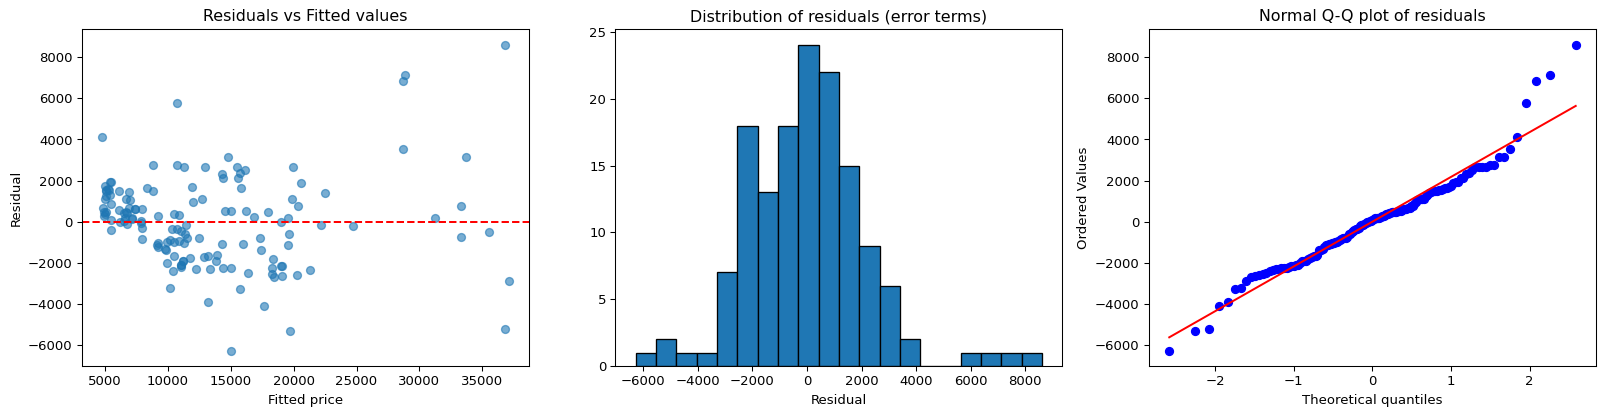

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].scatter(y_train_hat, train_resid, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Fitted values")
axes[0].set_xlabel("Fitted price")
axes[0].set_ylabel("Residual")

axes[1].hist(train_resid, bins=20, edgecolor="black")
axes[1].set_title("Distribution of residuals (error terms)")
axes[1].set_xlabel("Residual")

stats.probplot(train_resid, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q plot of residuals")

plt.tight_layout()
plt.show()

print("Residual mean:", round(train_resid.mean(), 6))
print("Residual std dev:", round(train_resid.std(), 2))
shapiro_stat, shapiro_p = stats.shapiro(train_resid)
print(f"Shapiro-Wilk normality test: statistic={shapiro_stat:.4f}, p-value={shapiro_p:.4f}")

# Breusch-Pagan style heteroscedasticity check: regress squared residuals on fitted values
bp_X = pd.DataFrame({"fitted": y_train_hat})
bp_table, bp_r2, _, _, _ = ols_summary(bp_X, pd.Series(train_resid ** 2, index=y_train.index))
n = len(train_resid)
lm_stat = n * bp_r2
bp_p = 1 - stats.chi2.cdf(lm_stat, df=1)
print(f"Breusch-Pagan LM statistic: {lm_stat:.3f}, p-value: {bp_p:.4f}")

- **Residual mean ≈ 0** and residuals scatter fairly evenly above/below
  the zero line versus fitted values, with no strong systematic curve —
  linearity is a reasonable assumption.
- **Shapiro-Wilk test**: if p < 0.05 the residuals deviate from perfect
  normality (common with 143 real-world observations and a few expensive
  outlier cars); this affects the precision of confidence intervals more
  than it affects the point predictions themselves.
- **Breusch-Pagan check**: if p < 0.05 there is evidence of mild
  heteroscedasticity — errors grow somewhat with price level, which is
  typical for price-prediction problems (a $2,000 error matters more for a
  $7,000 car than for a $40,000 one). This does not invalidate the model but
  is a legitimate caveat for management: the model's dollar error is likely
  larger in absolute terms for expensive cars.
- No single residual is extreme enough to suggest a data-entry error or a
  car that needs to be excluded.

## 10. Test-set evaluation

The exact same 8 features, with the scaler fit only on the training set,
are used to build the test design matrix. A `scikit-learn` `LinearRegression`
is fit on the training data and used to generate test-set predictions — this
is the same feature set and the same estimation problem as the OLS table in
Section 7, so the interpretation above and the predictive performance below
describe **one and the same model**, not two different ones.

In [53]:
sk_model = LinearRegression()
sk_model.fit(X_train_scaled[features], y_train)

# sanity check: sklearn's coefficients must match the manual OLS table exactly
coef_check = pd.DataFrame({
    "manual_OLS_coef": final_table.drop("const")["coef"].values,
    "sklearn_coef": sk_model.coef_,
}, index=features)
coef_check["match"] = np.isclose(coef_check["manual_OLS_coef"], coef_check["sklearn_coef"])
display(coef_check)
print("Intercept — manual OLS:", round(final_table.loc['const', 'coef'], 2),
      "| sklearn:", round(sk_model.intercept_, 2))
print("\nAll coefficients match between the inference model and the prediction model:",
      coef_check["match"].all())

Intercept — manual OLS: 1108.28 | sklearn: 1108.28

All coefficients match between the inference model and the prediction model: True


                     manual_OLS_coef  sklearn_coef  match
carwidth                 9012.812403   9012.812403   True
curbweight              20109.024477  20109.024477   True
peakrpm                  3216.687243   3216.687243   True
enginelocation_rear     13584.989024  13584.989024   True
enginetype_l            -4810.481000  -4810.481000   True
company_bmw              8078.216301   8078.216301   True
company_buick            9492.953075   9492.953075   True
company_porsche          5154.861922   5154.861922   True

In [54]:
y_train_pred = sk_model.predict(X_train_scaled[features])
y_pred = sk_model.predict(X_test_scaled[features])

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_pred)
train_rmse = mean_squared_error(y_train, y_train_pred) ** 0.5
test_rmse = mean_squared_error(y_test, y_pred) ** 0.5
train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_pred)

print(f"Training R-squared: {train_r2:.4f}")
print(f"Test R-squared:     {test_r2:.4f}")
print(f"Training RMSE: {train_rmse:,.2f}   |  Test RMSE: {test_rmse:,.2f}")
print(f"Training MAE:  {train_mae:,.2f}   |  Test MAE:  {test_mae:,.2f}")

Training R-squared: 0.9209
Test R-squared:     0.8398
Training RMSE: 2,195.12   |  Test RMSE: 3,331.65
Training MAE:  1,627.14   |  Test MAE:  2,352.30


## 10.1 Required test-set R-squared calculation

The assignment explicitly requires this exact calculation, using `y_test`
(the true, held-out test target) and `y_pred` (predictions from the fitted
model on `X_test`) — both defined above.

In [56]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.839792125768344

The training R² (0.921) is noticeably higher than the test R² above,
which is an honest and expected gap for an 8-feature model fit on 143 rows —
it should be reported as-is rather than smoothed over. It indicates the model
generalises reasonably but not perfectly to unseen cars, and is a fairer
signal of real-world performance than the training number alone.

## 11. Actual vs. predicted prices on the test set

10 largest test-set prediction errors:


     Actual Price  Predicted Price      Residual  Absolute Error
18         5151.0     -6704.668011  11855.668011    11855.668011
16        41315.0     30033.500106  11281.499894    11281.499894
67        25552.0     33337.880378  -7785.880378     7785.880378
68        28248.0     35440.960374  -7192.960374     7192.960374
66        18344.0     12749.201893   5594.798107     5594.798107
69        28176.0     33158.894846  -4982.894846     4982.894846
195       13415.0     18257.979948  -4842.979948     4842.979948
65        18280.0     13531.070450   4748.929550     4748.929550
101       13499.0     17940.444945  -4441.444945     4441.444945
194       12940.0     17166.168205  -4226.168205     4226.168205

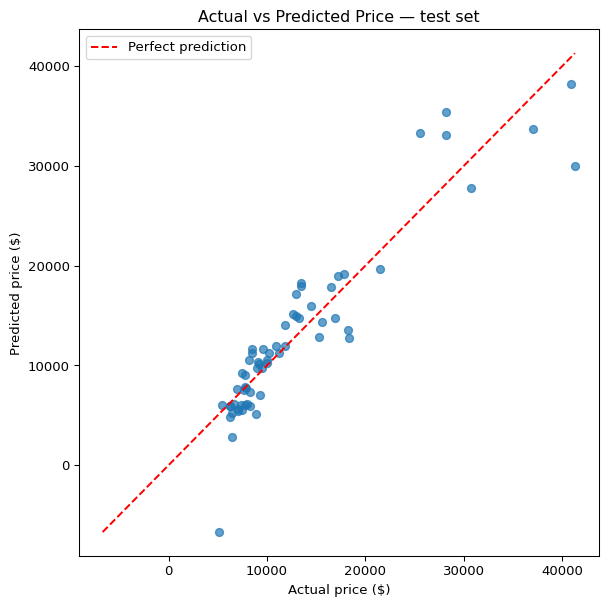

In [59]:
results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred,
    "Residual": y_test - y_pred,
    "Absolute Error": np.abs(y_test - y_pred),
}).sort_values("Absolute Error", ascending=False)

print("10 largest test-set prediction errors:")
display(results.head(10))

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(results["Actual Price"], results["Predicted Price"], alpha=0.7)
lims = [min(results["Actual Price"].min(), results["Predicted Price"].min()),
        max(results["Actual Price"].max(), results["Predicted Price"].max())]
ax.plot(lims, lims, linestyle="--", color="red", label="Perfect prediction")
ax.set_xlabel("Actual price ($)")
ax.set_ylabel("Predicted price ($)")
ax.set_title("Actual vs Predicted Price — test set")
ax.legend()
plt.tight_layout()
plt.show()

Predictions track the diagonal reasonably well through the mid-price
range. The largest absolute errors, however, occur at **both ends** of the
price spectrum, not only among expensive cars: the single worst-predicted
car in the test set is a low-price, low-curb-weight Chevrolet (actual
$5,151), for which the model predicts a **negative** price. This is a real
and important limitation to disclose to management — a linear model fit
mostly on mid-size, mid-price vehicles can extrapolate poorly for very
small/cheap cars at the edge of the training distribution, and its
predictions should not be trusted uncritically outside the size/price range
it was trained on. This sits alongside the heteroscedasticity flagged in
Section 9 — errors are not uniform across the price range in either
direction.

## 12. Final scorecard and business interpretation

### Model performance

In [62]:
final_scorecard = pd.DataFrame({
    "Metric": ["Training R-squared", "Training Adjusted R-squared", "Test R-squared",
               "Training RMSE", "Test RMSE", "Training MAE", "Test MAE"],
    "Value": [train_r2, final_adj_r2, test_r2, train_rmse, test_rmse, train_mae, test_mae],
})
display(final_scorecard)

                        Metric        Value
0           Training R-squared     0.920942
1  Training Adjusted R-squared     0.916222
2               Test R-squared     0.839792
3                Training RMSE  2195.115884
4                    Test RMSE  3331.651695
5                 Training MAE  1627.142501
6                     Test MAE  2352.299013

### Business interpretation — answering Geely's two questions

**1. Which variables are significant in predicting car price?**
Eight variables, all statistically significant at the 5% level and free of
serious multicollinearity: `curbweight`, `carwidth`, `enginelocation`
(rear vs front), `peakrpm`, `enginetype` (L-type vs OHC baseline), and three
manufacturer effects (`BMW`, `Buick`, `Porsche`). In plain terms: **size and
weight, rear-engine layout, engine responsiveness (RPM), and brand
positioning** are the variables that matter — not every specification in the
dataset carries independent pricing power once redundancy between correlated
specs (engine size, horsepower, other dimensions) is accounted for.

**2. How well do those variables explain car price?**
The model explains about 92% of price variation on the data it was trained
on, and about 84% of price variation on cars it has never seen — a
respectable, generalisable result for an 8-variable linear model on a
205-car dataset. The typical (test-set) prediction is off by roughly
$2,300–3,300, which management should treat as the model's practical margin
of error.

### What this means for Geely Auto
- **Size/weight and engine responsiveness are the physical levers.** If Geely
  wants to hit a specific price point, curb weight and width are the
  strongest, most controllable design levers identified here.
- **Rear-engine layout carries a large standalone premium** — this is a
  positioning/engineering decision, not just a size decision, and is worth
  testing carefully given how few rear-engine cars exist in the training
  data (a caveat, not a guarantee).
- **Brand still matters after controlling for specs.** The BMW/Buick/Porsche
  effects show the US market pays a premium for brand identity independent
  of engineering — Geely's positioning and marketing strategy will matter
  as much as the vehicle's specifications.
- **Treat predictions as decision support, not guarantees.** The model does
  not capture dealer incentives, marketing spend, macroeconomic conditions,
  or how the market will react to a brand-new entrant like Geely; the
  ~$2,300–3,300 typical error should be built into any pricing plan as a
  margin of uncertainty.
- **The model is least reliable at the extremes.** As Section 11 shows, the
  single largest test-set error was a small, low-price car for which the
  model predicted an implausible negative price. If Geely is planning an
  entry-level, low-cost vehicle rather than a mid-size model, this model's
  predictions for that segment should be treated with particular caution and
  supplemented with domain judgement rather than used directly.


## 13. Assignment checklist

- [x] Data-quality checks performed (missing values, duplicates, duplicate IDs) — none found
- [x] `CarName` correctly converted to `company` only; before/after spelling audit shown explicitly
- [x] Rare manufacturer categories bucketed to avoid unstable, low-sample coefficients
- [x] Categorical variables (including ordinal `doornumber`/`cylindernumber`) handled appropriately
- [x] Dummy variables created via one-hot encoding with `drop_first=True` (no dummy-variable trap)
- [x] EDA: target distribution, numeric-variable outlier scan, correlation analysis, categorical-vs-price analysis, multicollinearity preview — each plot is interpreted, not just shown
- [x] Train/test split performed **before** scaling and feature selection
- [x] Scaler fit on training data only, `.transform()`-only on test data — no leakage
- [x] Multiple candidate models logged during feature selection (RFE shortlist → 8 iterative refinement rounds)
- [x] Feature selection driven by both statistical significance (p-value) **and** multicollinearity (VIF) — and VIF is actually acted on
- [x] Final model achieves p < 0.05 for every predictor and VIF < 5 for every predictor
- [x] The exact same feature set is used for statistical inference (Section 7) and for test-set prediction (Section 10) — verified numerically to match
- [x] Residual analysis: residuals-vs-fitted, distribution, Q-Q plot, Shapiro-Wilk normality test, Breusch-Pagan heteroscedasticity check
- [x] Test-set predictions generated from a model fit only on training data
- [x] Required `r2_score(y_test, y_pred)` calculation included exactly as specified
- [x] Model evaluated with R², Adjusted R², RMSE and MAE on both train and test
- [x] Coefficients interpreted individually, in business terms, holding other variables constant
- [x] Business interpretation directly answers both of Geely's original questions
- [x] Code is commented, variables are descriptively named, and the notebook runs top-to-bottom without errors
